1. Configurar Entorno

In [1]:
#instalar librerías
!pip install -q pandas numpy matplotlib seaborn scikit-learn datasets mlflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 627.1 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 1.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 47.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 71.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 64.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [2]:
#importar librerías
import pandas as pd
import numpy as np
import sklearn
import datasets
import mlflow
import matplotlib
import seaborn

print("Entorno configurado correctamente")
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("MLflow:", mlflow.__version__)


Entorno configurado correctamente
Pandas: 2.2.3
Scikit-learn: 1.6.1
MLflow: 3.17.1


2. Dataset Inicial

In [7]:
#descargar dataset
from datasets import load_dataset

#cargar el dataset público de Bitext
dataset = load_dataset(
    "bitext/Bitext-customer-support-llm-chatbot-training-dataset"
)

#mostrar las partes disponibles del dataset
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['flags', 'instruction', 'category', 'intent', 'response'],
        num_rows: 26872
    })
})


In [9]:
#REVISAR LA ESTRUCTURA DE LOS DATOS

#convertir los datos de entrenamiento a un dataframe
df = dataset["train"].to_pandas()

#mostrar el tamaño del dataset
print("Filas y columnas:", df.shape)

#mostrar los nombres de las columnas
print("\nColumnas:")
print(df.columns.tolist())

#mostrar los primeros cinco registros
display(df.head())

Filas y columnas: (26872, 5)

Columnas:
['flags', 'instruction', 'category', 'intent', 'response']


,flags,instruction,category,intent,response
0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,I've understood you have a question regarding ...
1,BQZ,i have a question about cancelling oorder {{Or...,ORDER,cancel_order,I've been informed that you have a question ab...
2,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance wit...
3,BL,I need to cancel purchase {{Order Number}},ORDER,cancel_order,I understood that you need assistance with can...
4,BCELN,"I cannot afford this order, cancel purchase {{...",ORDER,cancel_order,I'm sensitive to the fact that you're facing f...


In [10]:
#REVISAR LA CALIDAD DE LOS DATOS

#revisar si hay valores vacíos
print("Valores vacíos por columna:")
print(df.isnull().sum())

#revisar si hay filas duplicadas
print("\nFilas duplicadas:", df.duplicated().sum())

#revisar cuántas categorías diferentes existen
print("\nNúmero de categorías:", df["category"].nunique())

#mostrar la cantidad de registros por categoría
print("\nRegistros por categoría:")
print(df["category"].value_counts())

#revisar algunos mensajes
display(df[["instruction", "category", "intent"]].head(10))

Valores vacíos por columna:
flags          0
instruction    0
category       0
intent         0
response       0
dtype: int64

Filas duplicadas: 0

Número de categorías: 11

Registros por categoría:
category
ACCOUNT         5986
ORDER           3988
REFUND          2992
CONTACT         1999
INVOICE         1999
PAYMENT         1998
FEEDBACK        1997
DELIVERY        1994
SHIPPING        1970
SUBSCRIPTION     999
CANCEL           950
Name: count, dtype: int64


,instruction,category,intent
0,question about cancelling order {{Order Number}},ORDER,cancel_order
1,i have a question about cancelling oorder {{Or...,ORDER,cancel_order
2,i need help cancelling puchase {{Order Number}},ORDER,cancel_order
3,I need to cancel purchase {{Order Number}},ORDER,cancel_order
4,"I cannot afford this order, cancel purchase {{...",ORDER,cancel_order
5,can you help me cancel order {{Order Number}}?,ORDER,cancel_order
6,"I can no longer afford order {{Order Number}},...",ORDER,cancel_order
7,I am trying to cancel purchase {{Order Number}},ORDER,cancel_order
8,I have got to cancel purchase {{Order Number}},ORDER,cancel_order
9,i need help canceling purchase {{Order Number}},ORDER,cancel_order


In [15]:
#guardar los datos originales
import os

#crear las carpetas del proyecto en colab
os.makedirs("datos/datos_ini", exist_ok=True)
os.makedirs("datos/datos_limp", exist_ok=True)
os.makedirs("fuentes", exist_ok=True)

#guardar el dataset original sin modificaciones
df.to_csv(
    "datos/datos_ini/bitext_original.csv",
    index=False,
    encoding="utf-8"
)

print("Dataset original guardado correctamente")
print("Número de registros:", len(df))
print("Archivo: datos/datos_ini/bitext_original.csv")

Dataset original guardado correctamente
Número de registros: 26872
Archivo: datos/datos_ini/bitext_original.csv


In [13]:
#descargar una copia del dataset original
from google.colab import files
files.download("datos/datos_ini/bitext_original.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

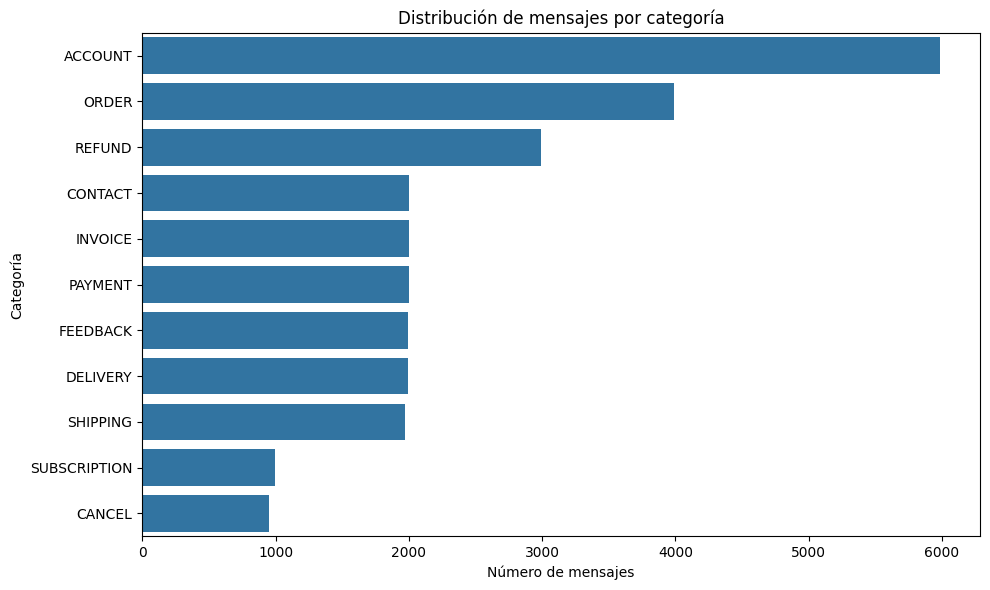

In [16]:
#DISTRIBUCIÓN DE CATEGORÍAS
import matplotlib.pyplot as plt
import seaborn as sns

#contar los registros de cada categoría
conteo_categorias = df["category"].value_counts()

#crear la gráfica
plt.figure(figsize=(10, 6))
sns.barplot(
    x=conteo_categorias.values,
    y=conteo_categorias.index
)

plt.title("Distribución de mensajes por categoría")
plt.xlabel("Número de mensajes")
plt.ylabel("Categoría")
plt.tight_layout()
plt.show()

count    26872.000000
mean         8.690979
std          2.605004
min          1.000000
25%          7.000000
50%          9.000000
75%         11.000000
max         16.000000
Name: longitud_mensaje, dtype: float64


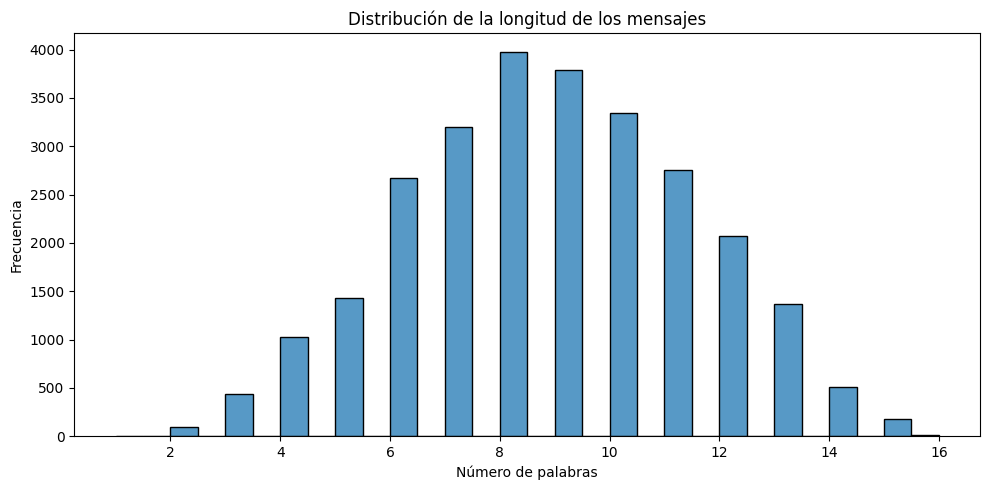

In [17]:
#LONGITUD DE LOS MENSAJES

#contar las palabras de cada mensaje
df["longitud_mensaje"] = df["instruction"].apply(
    lambda texto: len(texto.split())
)

#mostrar estadísticas generales
print(df["longitud_mensaje"].describe())

#crear un histograma
plt.figure(figsize=(10, 5))
sns.histplot(
    data=df,
    x="longitud_mensaje",
    bins=30
)

plt.title("Distribución de la longitud de los mensajes")
plt.xlabel("Número de palabras")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()


3. Dataset Limpio

In [19]:
#FUNCIÓN DE LIMPIEZA

def limpiar_datos(datos):
    #crear una copia para conservar los datos originales
    datos_limpios = datos.copy()

    #conservar las columnas que utilizaremos en la clasificación
    datos_limpios = datos_limpios[["instruction", "category"]]

    #eliminar espacios al inicio y al final de los mensajes
    datos_limpios["instruction"] = (
        datos_limpios["instruction"].str.strip()
    )

    #eliminar registros sin mensaje o sin categoría
    datos_limpios = datos_limpios.dropna(
        subset=["instruction", "category"]
    )

    #eliminar mensajes vacíos
    datos_limpios = datos_limpios[
        datos_limpios["instruction"] != ""
    ]

    #reiniciar los índices
    datos_limpios = datos_limpios.reset_index(drop=True)

    return datos_limpios


In [20]:
#APLICAR LIMPIEZA

df_limpio = limpiar_datos(df)

#comparar los datos antes y después de la limpieza
print("Registros originales:", len(df))
print("Registros limpios:", len(df_limpio))
print("Columnas finales:", df_limpio.columns.tolist())

#guardar el dataset limpio
df_limpio.to_csv(
    "datos/datos_limp/bitext_limpio.csv",
    index=False,
    encoding="utf-8"
)

print("\nDataset limpio guardado correctamente")


Registros originales: 26872
Registros limpios: 26872
Columnas finales: ['instruction', 'category']

Dataset limpio guardado correctamente


In [21]:
#descargar el dataset limpio
from google.colab import files
files.download("datos/datos_limp/bitext_limpio.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

4. Modelos


In [27]:
#DIVIDIR LOS DATODS

from sklearn.model_selection import train_test_split

#separar los mensajes y las categorías
X = df_limpio["instruction"]
y = df_limpio["category"]

#dividir los datos: 80 % entrenamiento y 20 % prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

#mostrar el tamaño de cada grupo
print("Registros totales:", len(df_limpio))
print("Datos de entrenamiento:", len(X_train))
print("Datos de prueba:", len(X_test))

#momprobar las categorías en los datos de entrenamiento
print("\nCategorías en entrenamiento:", y_train.nunique())
print("Categorías en prueba:", y_test.nunique())

Registros totales: 26872
Datos de entrenamiento: 21497
Datos de prueba: 5375

Categorías en entrenamiento: 11
Categorías en prueba: 11


In [28]:
#CONFIGURAR LA VALIDACIÓN CRUZADA

from sklearn.model_selection import GridSearchCV, StratifiedKFold

#dividir los datos de entrenamiento en 5 partes
validacion = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Validación cruzada configurada")

Validación cruzada configurada


In [29]:
#PREPARAR REGRESIÓN LOGÍSTICA

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

#crear el flujo de procesamiento y clasificación
pipeline_logistica = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("modelo", LogisticRegression(max_iter=1000))
])

#definir las combinaciones de parámetros
parametros_logistica = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "modelo__C": [0.5, 1.0, 2.0]
}

#configurar la búsqueda de los mejores parámetros
busqueda_logistica = GridSearchCV(
    estimator=pipeline_logistica,
    param_grid=parametros_logistica,
    scoring="f1_macro",
    cv=validacion,
    n_jobs=-1,
    verbose=1
)

print("Regresión Logística preparada")

Regresión Logística preparada


In [30]:
#PREPARAR NAIVE BAYES

from sklearn.naive_bayes import MultinomialNB

#crear el flujo de procesamiento y clasificación
pipeline_nb = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("modelo", MultinomialNB())
])

#definir las combinaciones de parámetros
parametros_nb = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "modelo__alpha": [0.5, 1.0, 1.5]
}

#configurar la búsqueda de los mejores parámetros
busqueda_nb = GridSearchCV(
    estimator=pipeline_nb,
    param_grid=parametros_nb,
    scoring="f1_macro",
    cv=validacion,
    n_jobs=-1,
    verbose=1
)

print("Naive Bayes preparado")

Naive Bayes preparado


In [32]:
#ENTRENAR REGRESIÓN LOGÍSTICA

import time

#medir el tiempo de entrenamiento y búsqueda
inicio = time.time()

busqueda_logistica.fit(X_train, y_train)

tiempo_logistica = time.time() - inicio

#mostrar los mejores resultados
print("Mejores parámetros:", busqueda_logistica.best_params_)
print("Mejor F1 macro en validación cruzada:",
      round(busqueda_logistica.best_score_, 4))
print("Tiempo de búsqueda:",
      round(tiempo_logistica, 2), "segundos")

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Mejores parámetros: {'modelo__C': 2.0, 'tfidf__ngram_range': (1, 2)}
Mejor F1 macro en validación cruzada: 0.998
Tiempo de búsqueda: 37.04 segundos


In [33]:
#ENTRENAR NAIVE BAYES

#medir el tiempo de entrenamiento y búsqueda
inicio = time.time()

busqueda_nb.fit(X_train, y_train)

tiempo_nb = time.time() - inicio

#mostrar los mejores resultados
print("Mejores parámetros:", busqueda_nb.best_params_)
print("Mejor F1 macro en validación cruzada:",
      round(busqueda_nb.best_score_, 4))
print("Tiempo de búsqueda:",
      round(tiempo_nb, 2), "segundos")

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Mejores parámetros: {'modelo__alpha': 0.5, 'tfidf__ngram_range': (1, 1)}
Mejor F1 macro en validación cruzada: 0.9975
Tiempo de búsqueda: 11.91 segundos


5. Evaluación

In [34]:
#evaluar los modelos con los datos de prueba

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

#obtener las predicciones de cada modelo
predicciones_logistica = busqueda_logistica.predict(X_test)
predicciones_nb = busqueda_nb.predict(X_test)

#crear una función para calcular las métricas
def evaluar_modelo(nombre, valores_reales, predicciones):
    return {
        "Modelo": nombre,
        "Accuracy": accuracy_score(valores_reales, predicciones),
        "Precision macro": precision_score(
            valores_reales, predicciones, average="macro",
            zero_division=0
        ),
        "Recall macro": recall_score(
            valores_reales, predicciones, average="macro",
            zero_division=0
        ),
        "F1 macro": f1_score(
            valores_reales, predicciones, average="macro",
            zero_division=0
        )
    }

#guardar los resultados en una tabla
resultados = pd.DataFrame([
    evaluar_modelo(
        "Regresión Logística", y_test, predicciones_logistica
    ),
    evaluar_modelo(
        "Naive Bayes", y_test, predicciones_nb
    )
])

# Mostrar los resultados redondeados
display(resultados.round(4))


,Modelo,Accuracy,Precision macro,Recall macro,F1 macro
0,Regresión Logística,0.9974,0.9982,0.9969,0.9975
1,Naive Bayes,0.9974,0.9978,0.9968,0.9973


In [35]:
from sklearn.metrics import roc_auc_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

#calcular ROC-AUC para clasificación multiclase
auc_logistica = roc_auc_score(
    y_test,
    busqueda_logistica.predict_proba(X_test),
    labels=busqueda_logistica.classes_,
    multi_class="ovr",
    average="macro"
)

auc_nb = roc_auc_score(
    y_test,
    busqueda_nb.predict_proba(X_test),
    labels=busqueda_nb.classes_,
    multi_class="ovr",
    average="macro"
)

print("ROC-AUC macro - Regresión Logística:",
      round(auc_logistica, 4))
print("ROC-AUC macro - Naive Bayes:",
      round(auc_nb, 4))


ROC-AUC macro - Regresión Logística: 1.0
ROC-AUC macro - Naive Bayes: 1.0


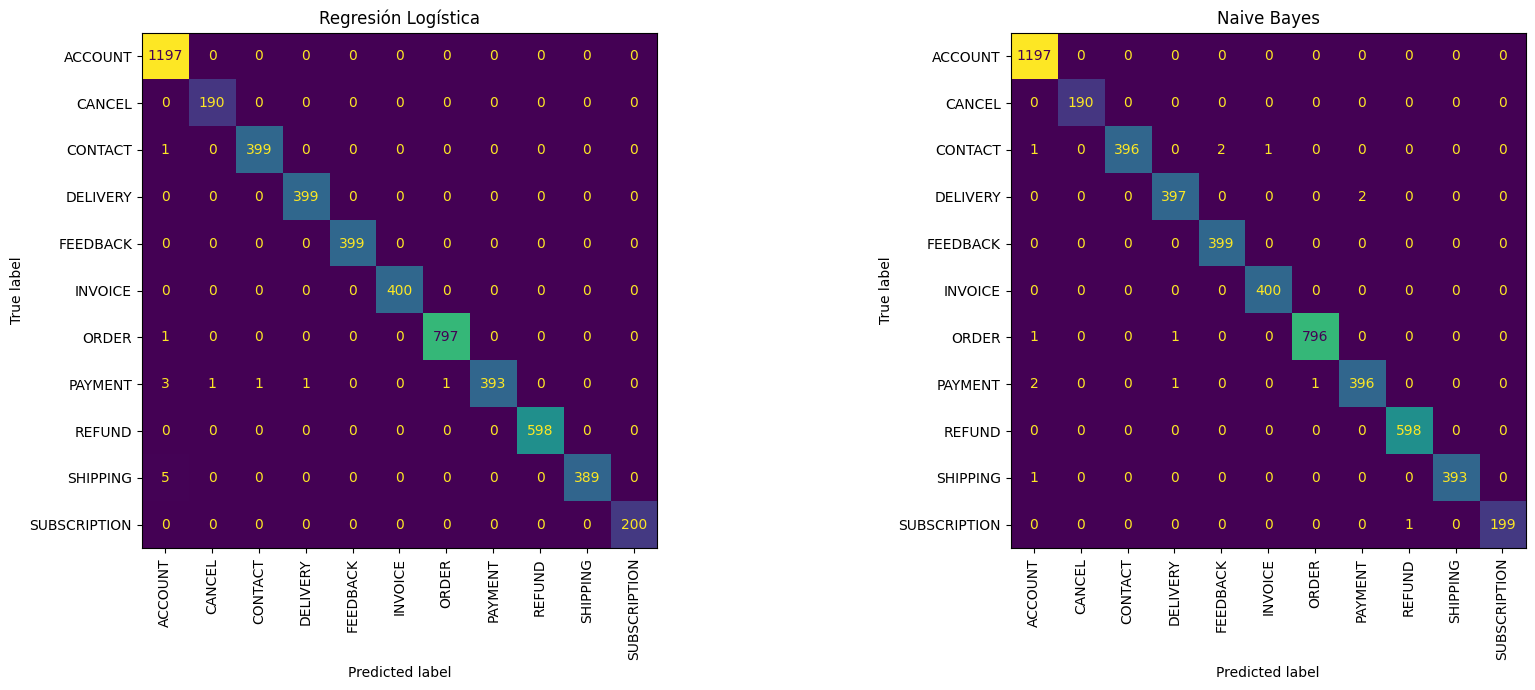

In [36]:
#mostrar las matrices de confusión
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predicciones_logistica,
    xticks_rotation=90,
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("Regresión Logística")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predicciones_nb,
    xticks_rotation=90,
    ax=axes[1],
    colorbar=False
)
axes[1].set_title("Naive Bayes")

plt.tight_layout()
plt.show()

6. MLflow

In [38]:
#configurar MLflow con SQLite
import mlflow
import mlflow.sklearn
import os

#crear una carpeta para guardar los archivos de los experimentos
os.makedirs("mlartifacts", exist_ok=True)

#usar una base de datos SQLite para registrar los experimentos
mlflow.set_tracking_uri("sqlite:///mlflow.db")

#crear o seleccionar el experimento
mlflow.set_experiment("Clasificacion_Mensajes_Atencion")

print("MLflow está configurado correctamente.")
print("Experimento: Clasificacion_Mensajes_Atencion")
print("Ubicación de los registros:", mlflow.get_tracking_uri())

2026/10/19 04:33:38 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/19 04:33:39 INFO mlflow.store.db.utils: Updating database tables
2026/10/19 04:33:43 INFO mlflow.tracking.fluent: Experiment with name 'Clasificacion_Mensajes_Atencion' does not exist. Creating a new experiment.


MLflow está configurado correctamente.
Experimento: Clasificacion_Mensajes_Atencion
Ubicación de los registros: sqlite:///mlflow.db


In [39]:
#REGISTRAR REGRESIÓN LOGÍSTICA EN MLFLOW

with mlflow.start_run(run_name="Regresion_Logistica"):

    #registrar los mejores parámetros encontrados
    mlflow.log_params(busqueda_logistica.best_params_)

    #registrar el tiempo de búsqueda
    mlflow.log_metric("tiempo_busqueda_segundos", tiempo_logistica)

    #registrar las métricas de prueba
    mlflow.log_metric(
        "accuracy", accuracy_score(y_test, predicciones_logistica)
    )
    mlflow.log_metric(
        "precision_macro",
        precision_score(
            y_test, predicciones_logistica,
            average="macro", zero_division=0
        )
    )
    mlflow.log_metric(
        "recall_macro",
        recall_score(
            y_test, predicciones_logistica,
            average="macro", zero_division=0
        )
    )
    mlflow.log_metric(
        "f1_macro",
        f1_score(
            y_test, predicciones_logistica,
            average="macro", zero_division=0
        )
    )
    mlflow.log_metric("roc_auc_macro", auc_logistica)

    #guardar el modelo entrenado
    mlflow.sklearn.log_model(
        sk_model=busqueda_logistica.best_estimator_,
        name="modelo_regresion_logistica"
    )

print("Regresión Logística registrada en MLflow")

Regresión Logística registrada en MLflow


In [40]:
#REGISTRAR NAIVE BAYES EN MLFLOW

with mlflow.start_run(run_name="Naive_Bayes"):

    #registrar los mejores parámetros encontrados
    mlflow.log_params(busqueda_nb.best_params_)

    #registrar el tiempo de búsqueda
    mlflow.log_metric("tiempo_busqueda_segundos", tiempo_nb)

    #registrar las métricas de prueba
    mlflow.log_metric(
        "accuracy", accuracy_score(y_test, predicciones_nb)
    )
    mlflow.log_metric(
        "precision_macro",
        precision_score(
            y_test, predicciones_nb,
            average="macro", zero_division=0
        )
    )
    mlflow.log_metric(
        "recall_macro",
        recall_score(
            y_test, predicciones_nb,
            average="macro", zero_division=0
        )
    )
    mlflow.log_metric(
        "f1_macro",
        f1_score(
            y_test, predicciones_nb,
            average="macro", zero_division=0
        )
    )
    mlflow.log_metric("roc_auc_macro", auc_nb)

    #guardar el modelo entrenado
    mlflow.sklearn.log_model(
        sk_model=busqueda_nb.best_estimator_,
        name="modelo_naive_bayes"
    )

print("Naive Bayes registrado en MLflow")

Naive Bayes registrado en MLflow


In [41]:
#consultar los experimentos registrados
experimento = mlflow.get_experiment_by_name(
    "Clasificacion_Mensajes_Atencion"
)

#obtener las ejecuciones del experimento
ejecuciones = mlflow.search_runs(
    experiment_ids=[experimento.experiment_id]
)

#mostrar el nombre, estado y métricas principales
columnas = [
    "tags.mlflow.runName",
    "status",
    "metrics.accuracy",
    "metrics.f1_macro",
    "metrics.roc_auc_macro",
    "metrics.tiempo_busqueda_segundos"
]

display(ejecuciones[columnas].round(4))

,tags.mlflow.runName,status,metrics.accuracy,metrics.f1_macro,metrics.roc_auc_macro,metrics.tiempo_busqueda_segundos
0,Naive_Bayes,FINISHED,0.9974,0.9973,1.0,11.9085
1,Regresion_Logistica,FINISHED,0.9974,0.9975,1.0,37.0380


In [46]:
#GUARDAR LA COMPARACIÓN DE MODELOS

#seleccionar las columnas de interés
comparacion_mlflow = ejecuciones[[
    "tags.mlflow.runName",
    "status",
    "params.modelo__C",
    "params.modelo__alpha",
    "params.tfidf__ngram_range",
    "metrics.accuracy",
    "metrics.precision_macro",
    "metrics.recall_macro",
    "metrics.f1_macro",
    "metrics.roc_auc_macro",
    "metrics.tiempo_busqueda_segundos"
]].copy()

#cambiar los nombres de las columnas para facilitar su lectura
comparacion_mlflow.columns = [
    "Modelo",
    "Estado",
    "C_Regresion_Logistica",
    "Alpha_Naive_Bayes",
    "Ngramas",
    "Accuracy",
    "Precision_macro",
    "Recall_macro",
    "F1_macro",
    "ROC_AUC_macro",
    "Tiempo_busqueda_segundos"
]

#guardar la tabla
comparacion_mlflow.to_csv(
    "comparacion_modelos_mlflow.csv",
    index=False
)

display(comparacion_mlflow.round(4))

print("\nTabla guardada como comparacion_modelos_mlflow.csv")

,Modelo,Estado,C_Regresion_Logistica,Alpha_Naive_Bayes,Ngramas,Accuracy,Precision_macro,Recall_macro,F1_macro,ROC_AUC_macro,Tiempo_busqueda_segundos
0,Naive_Bayes,FINISHED,None,0.5,"(1, 1)",0.9974,0.9978,0.9968,0.9973,1.0,11.9085
1,Regresion_Logistica,FINISHED,2.0,None,"(1, 2)",0.9974,0.9982,0.9969,0.9975,1.0,37.0380



Tabla guardada como comparacion_modelos_mlflow.csv


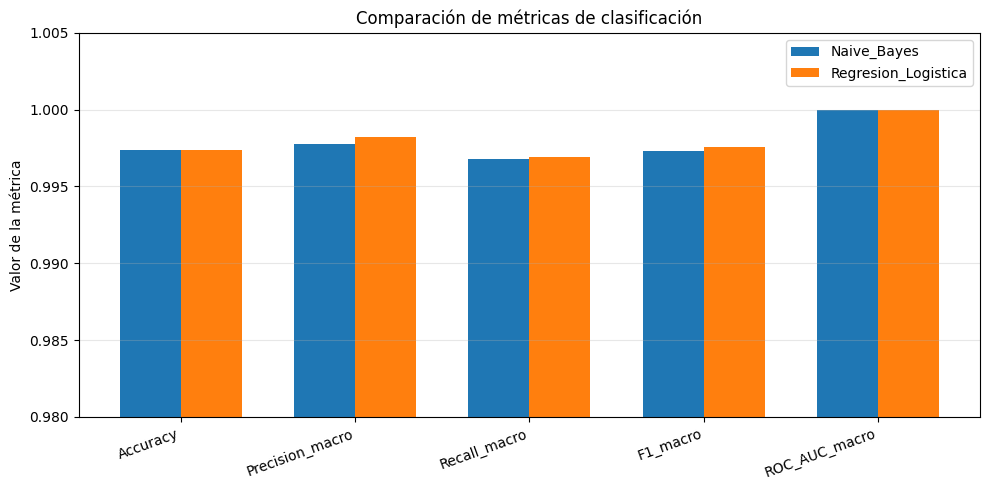


Gráfica guardada como comparacion_metricas.png


In [47]:
#comparar las métricas de los modelos
import matplotlib.pyplot as plt
import numpy as np

#seleccionar las métricas que vamos a comparar
metricas = ["Accuracy", "Precision_macro", "Recall_macro", "F1_macro",
            "ROC_AUC_macro"]

#preparar los valores de cada modelo
nombres = comparacion_mlflow["Modelo"].tolist()
valores = comparacion_mlflow[metricas].values

#crear la gráfica
x = np.arange(len(metricas))
ancho = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

for i, nombre in enumerate(nombres):
    ax.bar(
        x + (i - (len(nombres) - 1) / 2) * ancho,
        valores[i],
        ancho,
        label=nombre
    )

ax.set_title("Comparación de métricas de clasificación")
ax.set_ylabel("Valor de la métrica")
ax.set_xticks(x)
ax.set_xticklabels(metricas, rotation=20, ha="right")
ax.set_ylim(0.98, 1.005)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("comparacion_metricas.png", dpi=300)
plt.show()

print("\nGráfica guardada como comparacion_metricas.png")

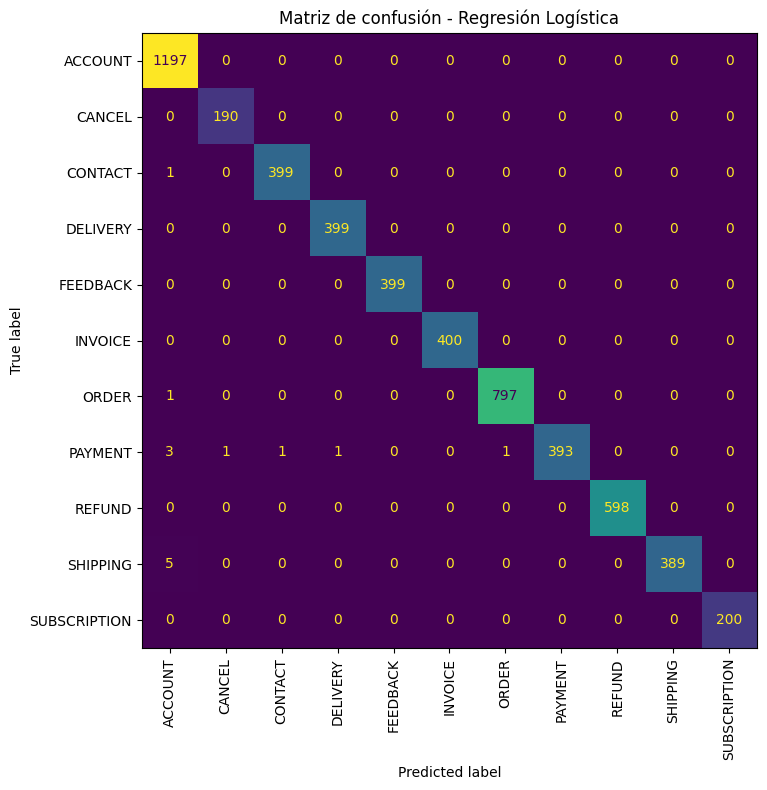

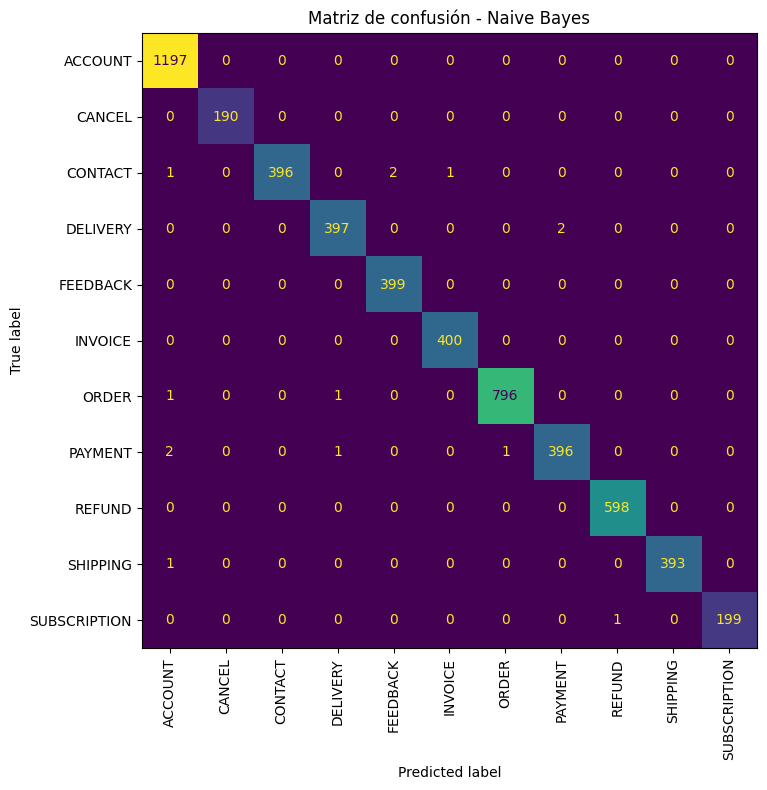


Matrices de confusión guardadas correctamente


In [49]:
#guardar las matrices de confusión
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

#matriz de confusión de Regresión Logística
fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predicciones_logistica,
    xticks_rotation=90,
    ax=ax,
    colorbar=False
)

ax.set_title("Matriz de confusión - Regresión Logística")
plt.tight_layout()
plt.savefig("matriz_regresion_logistica.png", dpi=300)
plt.show()

#matriz de confusión de Naive Bayes
fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predicciones_nb,
    xticks_rotation=90,
    ax=ax,
    colorbar=False
)

ax.set_title("Matriz de confusión - Naive Bayes")
plt.tight_layout()
plt.savefig("matriz_naive_bayes.png", dpi=300)
plt.show()

print("\nMatrices de confusión guardadas correctamente")

In [53]:
#descargar las evidencias de resultados
from google.colab import files

archivos_evidencia = [
    "comparacion_metricas.png",
    "matriz_regresion_logistica.png",
    "matriz_naive_bayes.png",
    "comparacion_modelos_mlflow.csv"
]

for archivo in archivos_evidencia:
    files.download(archivo)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [54]:
#revisar los archivos del proyecto
import os

for carpeta, subcarpetas, archivos in os.walk("."):
    #mostrar las carpetas y archivos relacionados con MLflow
    if (
        "mlflow" in carpeta.lower()
        or "mlartifacts" in carpeta.lower()
        or "mlruns" in carpeta.lower()
    ):
        print("\nCarpeta:", carpeta)

        for archivo in archivos[:10]:
            print(" -", archivo)


Carpeta: ./mlruns

Carpeta: ./mlruns/1

Carpeta: ./mlruns/1/models

Carpeta: ./mlruns/1/models/m-61c4056fcf08468baa7322a1cfe9ec3a

Carpeta: ./mlruns/1/models/m-61c4056fcf08468baa7322a1cfe9ec3a/artifacts
 - python_env.yaml
 - requirements.txt
 - MLmodel
 - model.skops
 - conda.yaml

Carpeta: ./mlruns/1/models/m-6d52442775e54a06a803b088aadb8c6d

Carpeta: ./mlruns/1/models/m-6d52442775e54a06a803b088aadb8c6d/artifacts
 - python_env.yaml
 - requirements.txt
 - MLmodel
 - model.skops
 - conda.yaml

Carpeta: ./mlartifacts


In [55]:
#revisar los archivos guardados de MLflow
import os

#buscar la base de datos de MLflow
for carpeta, subcarpetas, archivos in os.walk("."):
    for archivo in archivos:
        if archivo == "mlflow.db":
            ruta = os.path.join(carpeta, archivo)
            tamaño = os.path.getsize(ruta) / (1024 * 1024)
            print(f"Base de datos: {ruta}")
            print(f"Tamaño: {tamaño:.2f} MB")

#revisar los modelos guardados
for carpeta, subcarpetas, archivos in os.walk("./mlruns"):
    if "MLmodel" in archivos:
        print("Modelo guardado en:", carpeta)

Base de datos: ./mlflow.db
Tamaño: 0.91 MB
Modelo guardado en: ./mlruns/1/models/m-61c4056fcf08468baa7322a1cfe9ec3a/artifacts
Modelo guardado en: ./mlruns/1/models/m-6d52442775e54a06a803b088aadb8c6d/artifacts


In [56]:
#crear respaldo de MLflow
import os
import zipfile
from google.colab import files

#archivos y carpetas que queremos conservar
elementos = [
    "mlflow.db",
    "mlruns",
    "mlartifacts"
]

with zipfile.ZipFile(
    "respaldo_mlflow.zip", "w", zipfile.ZIP_DEFLATED
) as zip_respaldo:

    for elemento in elementos:
        if os.path.isfile(elemento):
            zip_respaldo.write(elemento)

        elif os.path.isdir(elemento):
            for carpeta, subcarpetas, archivos in os.walk(elemento):
                for archivo in archivos:
                    ruta = os.path.join(carpeta, archivo)
                    zip_respaldo.write(ruta)

print("Respaldo creado correctamente")
files.download("respaldo_mlflow.zip")

Respaldo creado correctamente


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

7. Comparación Estadística

In [57]:
#revisar si tenemos las variables de la comparación
print("y_test:", "y_test" in globals())
print("Predicciones de Regresion Logistica:",
      "predicciones_logistica" in globals())
print("Predicciones de Naive Bayes:",
      "predicciones_nb" in globals())

y_test: True
Predicciones de Regresion Logistica: True
Predicciones de Naive Bayes: True


In [59]:
#Comparacion estadistica de los modelos
from scipy.stats import binomtest
import pandas as pd

#Identificar que predicciones fueron correctas
correctas_logistica = (
    predicciones_logistica == y_test
)

correctas_nb = (
    predicciones_nb == y_test
)

#Contar los casos donde los modelos difieren
logistica_correcta_nb_error = sum(
    correctas_logistica & ~correctas_nb
)

nb_correcta_logistica_error = sum(
    correctas_nb & ~correctas_logistica
)

#Aplicar la prueba estadistica de McNemar usando la prueba binomial exacta
casos_diferentes = (
    logistica_correcta_nb_error
    + nb_correcta_logistica_error
)

if casos_diferentes > 0:
    resultado = binomtest(
        logistica_correcta_nb_error,
        n=casos_diferentes,
        p=0.5,
        alternative="two-sided"
    )
    valor_p = resultado.pvalue
else:
    valor_p = 1.0

#Mostrar los resultados
tabla_mcnemar = pd.DataFrame({
    "Resultado": [
        "Logistica correcta y Naive Bayes incorrecto",
        "Naive Bayes correcto y Logistica incorrecta",
        "Total de casos con resultados diferentes",
        "Valor p"
    ],
    "Cantidad": [
        logistica_correcta_nb_error,
        nb_correcta_logistica_error,
        casos_diferentes,
        round(valor_p, 6)
    ]
})

display(tabla_mcnemar)

#Interpretacion con un nivel de significancia del 5 %
if valor_p < 0.05:
    print("\nLa diferencia entre los modelos es estadisticamente significativa")
else:
    print("\nNo se encontro evidencia suficiente de una diferencia estadisticamente significativa")

,Resultado,Cantidad
0,Logistica correcta y Naive Bayes incorrecto,7.0
1,Naive Bayes correcto y Logistica incorrecta,7.0
2,Total de casos con resultados diferentes,14.0
3,Valor p,1.0



No se encontro evidencia suficiente de una diferencia estadisticamente significativa
